In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

Variable Definitions

In [2]:
TSN = 200157867
d = 867
alpha = 0.3 + d/5000

x_min = 1/np.sqrt(alpha)
deltax = 8/600

# grid
xpos = np.linspace(-4, 4, 601)

Potential Function V(x)

In [3]:
def V(x, alpha):

    V = alpha*x**4 - 2*x**2 + 1/alpha

    return V

### Problem A:

Initial Wavefunction $\psi_+(x)$

In [44]:
# initial wavefunction definition
omega = 2 * np.sqrt(2)
def psiplus(x):

    psiplus = (omega/np.pi)**(1/4) * np.exp(-(omega/2) * (x-x_min)**2)

    return psiplus

# initial potential function def
def Vplus(x):

    Vplus = 4 * (x-x_min)**2

    return Vplus

In [45]:
# left well wavefunction def
def psiminus(x):

    psiminus = (omega/np.pi)**(1/4) * np.exp(-(omega/2) * (x+x_min)**2)

    return psiminus

# left well wavefunction def
def Vminus(x):

    Vminus = 4 * (x+x_min)**2

    return Vminus

Propagator defintion $K(x_b, \epsilon; x_a, 0)=exp[i(\frac{1}{2}\frac{(x_b-x_a)^2}{\epsilon}-V(\frac{(x_b+x_a)}{2})\epsilon)]$

In [7]:
def K(xb, xa, eps):

    K = np.exp(1j * (1/2 * ((xb-xa)**2/eps) - V((xb+xa)/2, alpha) * eps))

    return K

Propagator as matrix with dimension 601$\times$601

In [8]:
# initialize
Keps = np.zeros([601, 601],  dtype=np.complex128)

eps = np.pi/128
# Propagator Matrix
for i in range(601):      
    for j in range(601):

        Keps[i, j] = K(xpos[i], xpos[j], eps)

i) Run and Plot

In [9]:
# define a function for propagating t timesteps

def propagate(t):
    time = []
    psi_t = np.zeros([t, 601], dtype = np.complex128)
    x_exp_t = np.zeros(t, dtype = np.float128)
    # initial wavefunction
    psi_ini = psiplus(xpos)

    # Propagated wavefunction at time step t:
    for i in range(t):

        if i == 0:
            psi_t[i] = psi_ini
        else:
            psi_next = deltax * Keps @ psi_t[i-1]
            normalization = np.sqrt(deltax * np.sum(np.abs(psi_next) ** 2))
            psi_t[i] = psi_next / normalization

        x_exp_t[i] = deltax * np.sum(xpos * np.abs(psi_t[i]) ** 2)

        time.append(i * eps)
        
    return time, x_exp_t

Plot

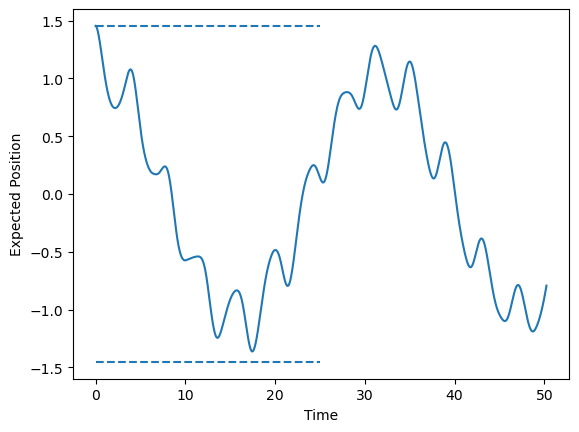

In [10]:
time, x_exp_t = propagate(16*128)

plt.plot(time, x_exp_t)
# formatting
plt.hlines(-x_min, 0, 25, linestyles='--', label='-x_min')
plt.hlines(x_min, 0, 25, linestyles='--', label='-x_min')
plt.xlabel("Time")
plt.ylabel("Expected Position")
plt.show()

## Problem B

In [11]:
import scipy
from scipy.sparse.linalg import eigsh

Define Hamiltonian Matrix

In [12]:
# create hamiltonian matrix
def H(x, alpha, deltax):
    
    H_ii = 1 / (deltax**2) + V(x, alpha)           # diagonal entries
    H_offdia = np.full(np.size(x)-1, -1 / (2 * deltax**2))  # off-diagonal entries

    H = np.diag(H_ii)
    H += np.diag(H_offdia, 1)
    H += np.diag(H_offdia, -1)

    return H

i)

In [13]:
H_04 = H(xpos, 0.4, deltax)
H_06 = H(xpos, 0.6, deltax)


w04, v04 = scipy.sparse.linalg.eigsh(H_04, k = 2, sigma = 0)
w06, v06 = scipy.sparse.linalg.eigsh(H_06, k = 2, sigma = 0)

print(w04)
print(w06)

[1.23447724 1.34690427]
[1.06247981 1.42104358]


Table I values:

$\lambda = 0.10$: $E_0 = 1.234507162786, E_1 = 1.346940868922$ \
$\lambda = 0.15$: $E_0 = 1.062499247956, E_1 = 1.421086890593$ 

The first 4 decimal digits are the same. The limiting factors maybe the granularity of each x position since the original work worked with a continuous distribution of x positions rather than discrete.


ii)

In [14]:
H_original = H(xpos, alpha, deltax)

xposhs = np.linspace(-4, 4, 1200)
H_halfspacing = H(xposhs, alpha, 8/1200)

xposlb = np.linspace(-6, 6, 900)
H_largebox = H(xposlb, alpha, 8/600)

worg, vorig = scipy.sparse.linalg.eigsh(H_original, k = 2, sigma = 0)
whs, vhs = scipy.sparse.linalg.eigsh(H_halfspacing, k = 2, sigma = 0)
wlb, vlb = scipy.sparse.linalg.eigsh(H_largebox, k = 2, sigma = 0)

In [15]:
print(worg, worg[1]-worg[0])
print(whs, whs[1]-whs[0])
print(wlb, wlb[1]-wlb[0])

[1.16853196 1.36638871] 0.19785674470007164
[1.16916984 1.36769091] 0.1985210636227479
[1.16935727 1.36808724] 0.19872997194343966


The energy spacing is bigger when the spacing between the positions is smaller; the energy spacing also increases with a wider distribution of positions

In [86]:
vorg0 = vorig[:, 0]
vorg1 = vorig[:, 1]

# normalization of the eigenvectors

def normalize(v, deltax):

    A = np.sqrt((1 / deltax) / np.sum(np.abs(v) ** 2))
    vnorm = v / A

    return A, vnorm

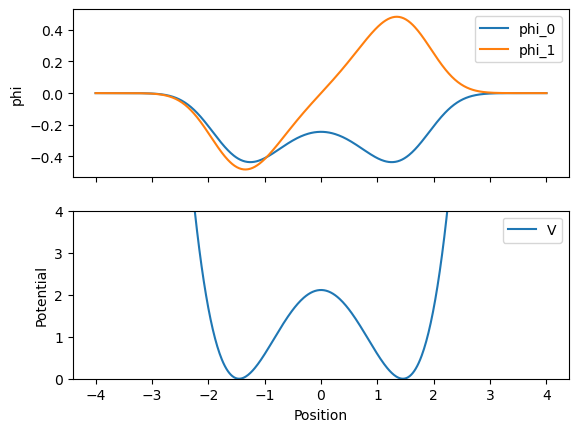

In [87]:
# normalize and plot
# normalization factor
A, _ = normalize(vorg0 + vorg1, deltax)
vorgnorm0 = vorg0 * A
vorgnorm1 = vorg1 * A

f, (ax1, ax2) = plt.subplots(2, 1, sharex = True)
ax1.plot(xpos, vorgnorm0, label = "phi_0")
ax1.plot(xpos, vorgnorm1, label = "phi_1")
ax2.plot(xpos, V(xpos, alpha), label = "V")

ax1.legend()
ax2.legend()
ax1.set(ylabel = "phi")
ax2.set(xlabel = "Position", ylabel = "Potential")
ax2.set_ylim(0, 4);

## Problem C

i)

In [59]:
psis = 1/np.sqrt(2) * (psiplus(xpos) + psiminus(xpos))
psia = 1/np.sqrt(2) * (psiplus(xpos) - psiminus(xpos))

E_s = np.vdot(psis, H(xpos, alpha, deltax) @ psis)/ (np.sum(np.abs(psis)**2))
E_a = np.vdot(psia, H(xpos, alpha, deltax) @ psia)/ (np.sum(np.abs(psia)**2))
print(f"E_S = {E_s}, E_A = {E_a}, E_A - E_S = {E_a - E_s}")

E_S = 1.4397887030658305, E_A = 1.4774082830321171, E_A - E_S = 0.03761957996628662


Relative errors

In [89]:
# retrieve calculated energies from part B
E_0 = worg[0]
E_1 = worg[1]

# calculate relative error
Rerror0 = np.abs(E_s - E_0) / np.abs(E_0)
Rerror1 = np.abs(E_a - E_1) / np.abs(E_1)

# calculate gap error
Gerror = ((E_a - E_1) - (E_s - E_0))/ np.abs(E_1 - E_0)

print(f"Relative Errors: E_0 = {Rerror0}, E_1 = {Rerror1}")
print(f"Gap Errors: = {Gerror}")

Relative Errors: E_0 = 0.23213463458575287, E_1 = 0.08125036078892847
Gap Errors: = -0.8098645561802119


From the calculations, the energies are more accurate

ii)

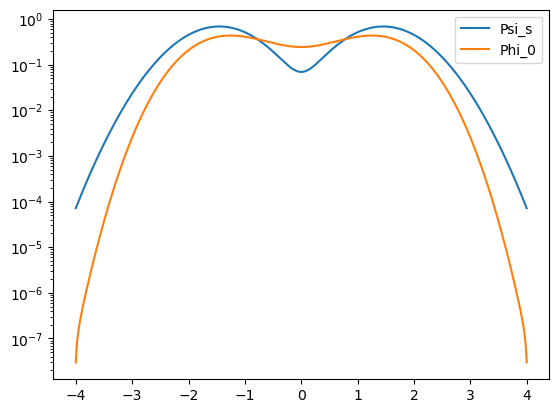

In [88]:
# normalize psi_s
_, psisnorm = normalize(psis, deltax)

# plot
fig, ax = plt.subplots(1, 1)
ax.plot(xpos, np.abs(psisnorm), label = "Psi_s")
ax.plot(xpos, np.abs(vorgnorm0), label = "Phi_0")
ax.set_yscale('log')
ax.legend()

The local harmonic approximation assumes that the two wells have two independent potentials of the harmonic oscillator, so the connection between the potentials is sharp. Unlike the real case where there is width between the two minimums of potential, and the amplitude of the potential at the barrier is finite.

## Problem D

i)

$\langle x \rangle (t) = \int_{-4}^4 x|\psi(x,t)|^2dx$ 

$ = \int_{-4}^4 x|\phi_0(x,t)|^2dx + \int_{-4}^4 x|\phi_1(x,t)|^2dx$
$+ \int_{-4}^4 e^{i(E_0-E_1)t/\hbar} \phi_0(x)^* x \phi_1(x)dx + \int_{-4}^4 e^{-i(E_0-E_1)t/\hbar} \phi_1(x)^* x \phi_0(x)dx $ 

Since the expected position value for $\phi_0$ is exactly the opposite \
of $\phi_1$ (e.g. the two minimas of the potential), we are left with 

$\int_{-4}^4 e^{i(E_0-E_1)t/\hbar} \phi_0(x)^* x \phi_1(x)dx + \int_{-4}^4 e^{-i(E_0-E_1)t/\hbar} \phi_1(x)^* x \phi_0(x)dx $

Since $\phi_{0/1} = \phi_{0/1}^*$ \
$ \langle x \rangle (t) = x_{01}cos(\Delta Et/\hbar)$ 

Then the half period of oscillation or cosine ($1\rightarrow -1$) is just $t_{tunnel} = \frac{\pi\hbar}{\Delta E}$
